# Paper figure: glyphs and member labels

In [1]:
from pathlib import Path

import io
import re

import matplotlib as mpl
import matplotlib.pyplot as plt
from pypdf import PdfReader, PdfWriter

import eunoia as eu

OUT = Path("C:/Users/user/Documents/GitHub/eunoia/paper/images")
OUT.mkdir(parents=True, exist_ok=True)

# Match the existing paper figures: DejaVu Sans, text as paths in SVG,
# embedded TrueType fonts in PDF.
mpl.rcParams.update({
    "font.family": "DejaVu Sans",
    "svg.fonttype": "path",
    "pdf.fonttype": 42,
})

# Same as CELL_MM in paper/make-figures.mjs: 55 mm per panel, so two
# panels side by side are 110 mm wide. Height is trimmed on save.
CELL_MM = 55
FIG_W_IN = 2 * CELL_MM / 25.4
FIG_H_IN = 60 / 25.4

# Draw the figure SCALE times bigger so the glyphs have room, then shrink
# the saved SVG/PDF back down by the same factor. Everything shrinks,
# text included, so the final text is fontsize / SCALE.
SCALE = 4

## Data

In [2]:
# Left panel: counts per exclusive region, one glyph per unit
glyph_sets = {
    "A": 20,
    "B": 14,
    "C": 18,
    "A&B": 6,
    "A&C": 5,
    "B&C": 4,
    "A&B&C": 2,
}

# Right panel: gene names per exclusive region, six in the triple overlap
genes = [f"gene{i:02d}" for i in range(1, 22)]
regions = {
    "A": genes[0:4],
    "B": genes[4:7],
    "C": genes[7:11],
    "A&B": genes[11:13],
    "A&C": genes[13:14],
    "B&C": genes[14:15],
    "A&B&C": genes[15:21],
}
member_sets = {
    s: [g for key, names in regions.items() if s in key.split("&") for g in names]
    for s in ["A", "B", "C"]
}
member_sets

{'A': ['gene01',
  'gene02',
  'gene03',
  'gene04',
  'gene12',
  'gene13',
  'gene14',
  'gene16',
  'gene17',
  'gene18',
  'gene19',
  'gene20',
  'gene21'],
 'B': ['gene05',
  'gene06',
  'gene07',
  'gene12',
  'gene13',
  'gene15',
  'gene16',
  'gene17',
  'gene18',
  'gene19',
  'gene20',
  'gene21'],
 'C': ['gene08',
  'gene09',
  'gene10',
  'gene11',
  'gene14',
  'gene15',
  'gene16',
  'gene17',
  'gene18',
  'gene19',
  'gene20',
  'gene21']}

## Figure

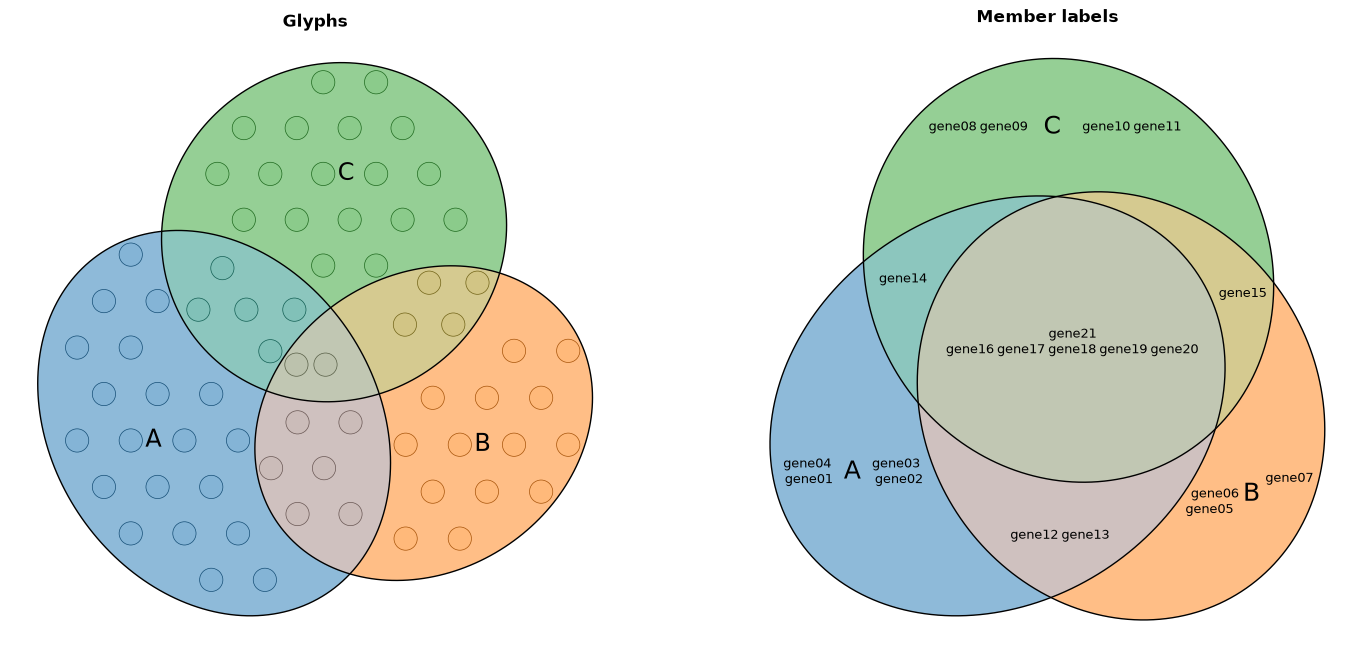

In [3]:
fit_glyphs = eu.euler(glyph_sets, shape="ellipse", seed=1)
fit_members = eu.euler(member_sets, shape="ellipse", seed=1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(FIG_W_IN * SCALE, FIG_H_IN * SCALE))
fit_glyphs.plot(ax=ax1, glyphs=True, labels={'fontsize':17})
fit_members.plot(ax=ax2, members={"mode": "packed", "fontsize":9, "scale":1}, labels={'fontsize':18})
ax1.set_title("Glyphs", fontweight="bold")
ax2.set_title("Member labels", fontweight="bold")
plt.show()

In [4]:
def save_svg(fig, path):
    buf = io.StringIO()
    fig.savefig(buf, format="svg", bbox_inches="tight", pad_inches=0.02 * SCALE)
    svg = buf.getvalue()

    # Shrink the root width/height; the viewBox keeps the content intact.
    def shrink(m):
        return f'{m.group(1)}="{float(m.group(2)) / SCALE:g}{m.group(3)}"'

    head, rest = svg.split("<svg", 1)
    tag, body = rest.split(">", 1)
    tag = re.sub(r'(width|height)="([\d.]+)(\w*)"', shrink, tag)
    path.write_text(head + "<svg" + tag + ">" + body, encoding="utf-8")


def save_pdf(fig, path):
    buf = io.BytesIO()
    fig.savefig(buf, format="pdf", bbox_inches="tight", pad_inches=0.02 * SCALE)
    buf.seek(0)
    writer = PdfWriter()
    for page in PdfReader(buf).pages:
        page.scale_by(1 / SCALE)
        writer.add_page(page)
    with open(path, "wb") as f:
        writer.write(f)


save_svg(fig, OUT / "features.svg")
save_pdf(fig, OUT / "features.pdf")
print("saved", OUT / "features.svg", "and .pdf")

saved C:\Users\user\Documents\GitHub\eunoia\paper\images\features.svg and .pdf
